In [42]:
!pip install gdown


In [43]:
import gdown
# File ID from your Google Drive link
field_id = "1rEp9gZKxykebTl1xr5bop2YER_FN5sDZ"
url = "https://drive.google.com/file/d/1rEp9gZKxykebTl1xr5bop2YER_FN5sDZ/view?usp=drive_link"
output_file = 'House Price Prediction Dataset.csv'
gdown.download(id = field_id, output= output_file, quiet= False)

Downloading...
From: https://drive.google.com/uc?id=1rEp9gZKxykebTl1xr5bop2YER_FN5sDZ
To: /content/House Price Prediction Dataset.csv
100%|██████████| 30.0k/30.0k [00:00<00:00, 18.5MB/s]


'House Price Prediction Dataset.csv'

In [44]:
!pip install pandas

In [45]:
# Data handling
import pandas as pd
import numpy as np

#visualization
import matplotlib.pyplot as plt
import seaborn as sns

#Model building
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler # Corrected import
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [46]:
import pandas as pd
#1.load dataset
df = pd.read_csv('House Price Prediction Dataset.csv')
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [47]:
#check dataset info and missing values
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


,0
price,0
area,0
bedrooms,0
bathrooms,0
stories,0
mainroad,0
guestroom,0
basement,0
hotwaterheating,0
airconditioning,0


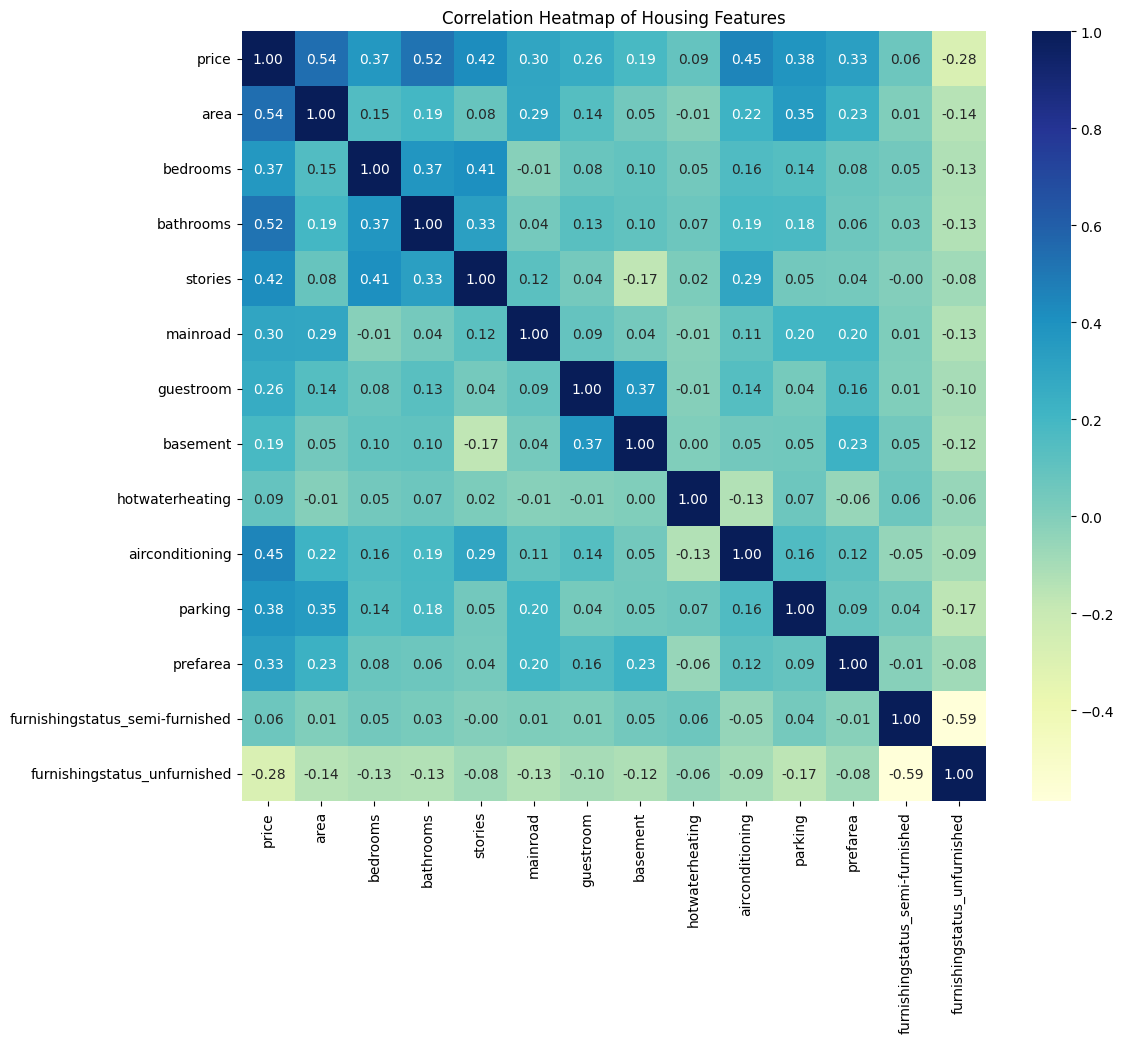

In [67]:
# 2. Data Cleaning and Preprocessing
# Convert binary categorical variables ('yes'/'no') into numerical (1/0)
binary_columns = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
for col in binary_columns:
    df[col] = df[col].map({'yes': 1, 'no': 0})

# Use One-hot encoding for categorical variables with more than 2 levels (furnishingstatus)
# drop_first=True prevents multi-collinearity by removing one redundant column
df = pd.get_dummies(df, columns=['furnishingstatus'], drop_first=True)

# 3. Exploratory Data Analysis (EDA) - Heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(), annot=True, cmap='YlGnBu', fmt='.2f')
plt.title('Correlation Heatmap of Housing Features')
plt.savefig('correlation_matrix.png')


In [49]:
#Fill categorical missing values with mode
for col in df.select_dtypes(include='object').columns:
  df[col].fillna(df[col].mode()[0], inplace=True)

#Fill numerical missing values with median
for col in df.select_dtypes(include='number').columns:
  df[col].fillna(df[col].median(), inplace=True)

#confirm no missing values remain
df.isnull().sum()

/tmp/ipython-input-1021098340.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mode()[0], inplace=True)
/tmp/ipython-input-1021098340.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try usi

,0
price,0
area,0
bedrooms,0
bathrooms,0
stories,0
mainroad,0
guestroom,0
basement,0
hotwaterheating,0
airconditioning,0


In [50]:
import pandas as pd

# Load the dataset
data = pd.read_csv('House Price Prediction Dataset.csv')

# Check the first few rows
data.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [51]:
#4.Preprocessing
from sklearn.model_selection import train_test_split
X = df.drop('price', axis=1)
y = df['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [68]:
# 5. Feature Scaling
# Scaling helps the model converge faster and treats all features equally
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [69]:
# 6. Model Training
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train_scaled, y_train)

LinearRegression()

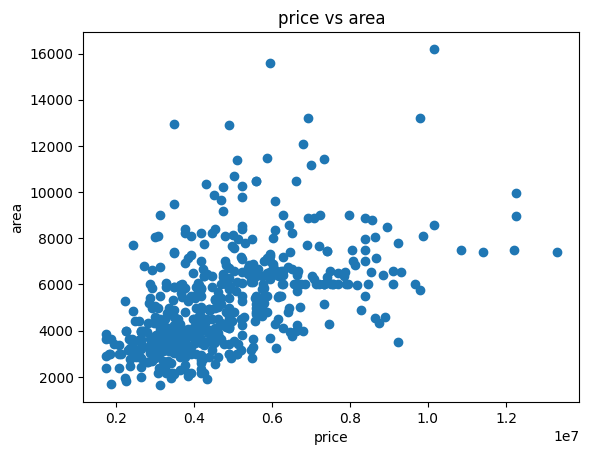

In [60]:
#scatter plot
import pandas as pd
import matplotlib.pyplot as plt

plt.scatter(data['price'], data['area'])
plt.title('price vs area')
plt.xlabel('price')
plt.ylabel('area')
plt.show()

In [61]:
#7. Model prediction and evalution

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Prepare the data
# Assuming 'data' DataFrame is available from a previous cell (e.g., gg8DzUprvKqO).
X = data[['price']]  # Features
y = data['area']     # Target

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f'MAE: {mae}')
print(f'MSE: {mse}')
print(f'RMSE: {rmse}')
print(f'R²: {r2}')

MAE: 1341.5115869796875
MSE: 2935124.125094529
RMSE: 1713.2203959486733
R²: 0.2863227465807432


In [62]:
#8. Feature Importance (Analysis of Coefficients)
coeffs = pd.DataFrame(model.coef_, X.columns, columns=['Coefficient']).sort_values(by='Coefficient', ascending=False)
print("\n--- Feature Coefficients ---")
print(coeffs)


--- Feature Coefficients ---
       Coefficient
price     0.000669


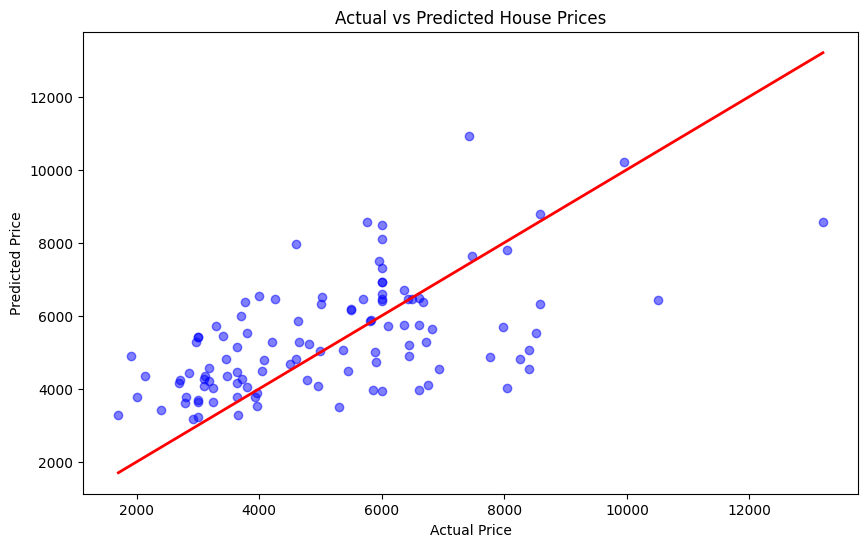

In [63]:
# 9. Visualization: Actual vs Predicted Prices
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, color='blue', alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', lw=2)
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted House Prices')
plt.savefig('actual_vs_predicted.png')
